# Step 7: Cold-Start Routing and Category Diversification

**BT4222 Final Project, Group 13, JDSearch**

Two review comments on the draft asked for (1) a separate scoring path for users with little history (current-query matching, product metadata and training popularity instead of the history features) and (2) a category-diversification step after relevance scoring. Step 7 **implements both on top of the Step 4 ranker, selects every setting on validation data only, and reports what they do to the test metrics**, whether or not the answer is flattering.

## How to read this notebook

Every code cell is cut verbatim from `src/step7_coldstart_diversity.py`, so the notebook and the script cannot drift apart
(`tests/test_notebooks.py` checks it). Each cell is preceded by a short explanation of what it does and
why, and the table below links every section to the function that implements it and to the file it
produces, so any number in the report can be traced back to a cell.

* **Part A** rebuilds the step. It needs the inputs listed below.
* **Part B** reads the measured outputs of the corrected run (`artifacts/corrected`) and re-checks them.
  It needs no raw data, so it always runs and its outputs are saved in this copy of the notebook.

| Section | What it does | Code in `src/step7_coldstart_diversity.py` | Writes |
|---|---|---|---|
| A.1 | Settings (history-free features, thresholds, lambdas) | `HISTORY_FREE`, `HISTORY_THRESHOLDS`, `LAMBDAS`, `TOP_K` | - |
| A.2 | Routing and diversification primitives | `route_scores`, `mmr_rerank`, `diversify`, `diversity_metrics` | - |
| A.3 | Load Steps 2 to 4 outputs | `main()` | - |
| A.4 | Full ranker and history-free fallback | `main()` | `lgb_fallback_history_free.txt` |
| A.5 | Cold-start threshold chosen on validation | `main()` | `coldstart_threshold_selection.csv` |
| A.6 | Test effect by history-length segment, paired bootstrap | `main()` | `coldstart_segments.csv` |
| A.7 | Diversity trade-off, lambda chosen on validation | `main()` | `diversity_tradeoff.csv`, `fig_diversity_tradeoff.png` |
| A.8 | Final scores and summary | `main()` | `test_pred_step7.parquet`, `results_coldstart_diversity.json` |
| B.1 | Saved cold-start results | - | - |
| B.2 | Saved diversity trade-off | - | - |

**Inputs.** `features.parquet`, `sessions.parquet`, `meta_subset.parquet` and, if present, the Step 4 booster `lgb_model.txt`.

**Outputs.** `results_coldstart_diversity.json`, `coldstart_segments.csv`, `coldstart_threshold_selection.csv`, `diversity_tradeoff.csv`, `test_pred_step7.parquet`, `lgb_fallback_history_free.txt`, `fig_diversity_tradeoff.png`.

> **Provenance of the outputs saved in this copy.** They were produced from the *draft* run's tables
> (26 October feature values; same 20,000-user sample and seed-42 split as the corrected run, verified
> by session id). The corrected `features.parquet` is too large to commit. Rerun Part A after Steps 2
> to 4 of the corrected pipeline and the numbers will be refreshed; the conclusions are expected to
> hold but must be re-measured, and the report says so.

## The two ideas in one paragraph each

**Cold-start router.** A second LambdaMART is trained on the 10 features that do **not** use the user's
history. Sessions whose history is at most `T` events long are scored by it, all others keep the full
model's score. The whole slate switches, so the two models' score scales never mix. `T` is picked on
validation, and `T = -1` ("never route") is the baseline it has to beat.

**Category diversification (MMR).** Greedy re-ranking of the top 10: at each position pick the item with the
best `(1 - lambda) * relevance - lambda * (items of the same level-3 category already chosen)`. `lambda = 0`
reproduces the relevance ranking exactly (unit-tested); positions after the top 10 keep relevance order.

## 0. Environment setup

The first cell finds the project and puts `src/` on `sys.path`, so `config`, `data_utils`
and `eval_utils` can be imported exactly as the scripts do.

* **In Colab** it clones the repository (branch set in `BRANCH`). Set `MOUNT_DRIVE = True` if the
  raw files live on Google Drive: raw paths and the output folder then point to Drive, so the
  outputs of one step survive until the next notebook.
* **Locally** it looks for `Final Project/` next to the notebook.
* All paths come from environment variables read by `src/config.py`:
  `JD_USER_TXT`, `JD_PRODUCT_TXT` (raw files), `JD_RUN_DIR` (where outputs are written, default
  `artifacts/corrected`), `JD_SEED` (default 42).

In [1]:
# Optional: install dependencies in a fresh environment (Colab already has most of them)
# !pip -q install numpy pandas pyarrow scipy scikit-learn lightgbm joblib matplotlib torch

import os, sys, subprocess
from pathlib import Path

REPO_URL = "https://github.com/steffanylars/nus-web-mining-business-insights.git"
BRANCH = "main"   # final submission branch
MOUNT_DRIVE = False                    # Colab only: True keeps raw data and outputs on Google Drive
DRIVE_DIR = "/content/drive/MyDrive/JDsearch"

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if MOUNT_DRIVE:
        from google.colab import drive
        drive.mount("/content/drive")
        os.environ.setdefault("JD_USER_TXT", f"{DRIVE_DIR}/user_behavior_data.txt")
        os.environ.setdefault("JD_PRODUCT_TXT", f"{DRIVE_DIR}/product_meta_data.txt")
        os.environ.setdefault("JD_RUN_DIR", f"{DRIVE_DIR}/runs/corrected")
    repo = Path("/content/nus-web-mining-business-insights")
    if not (repo / ".git").exists():
        subprocess.run(["git", "clone", "--branch", BRANCH, REPO_URL, str(repo)], check=True)
    PROJECT_ROOT = repo / "Final Project"
else:
    here = Path.cwd()
    options = [here, here.parent, here / "Final Project", here.parent / "Final Project"]
    PROJECT_ROOT = next((p for p in options if (p / "src" / "config.py").exists()), None)
    assert PROJECT_ROOT is not None, "open this notebook from Final Project/ or Final Project/notebooks/"

SRC = PROJECT_ROOT / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))
print("in Colab    :", IN_COLAB)
print("project root:", PROJECT_ROOT)
print("run dir     :", os.environ.get("JD_RUN_DIR", "<default: artifacts/corrected>"))

in Colab    : False
project root: Final Project
run dir     : draft_run


## 1. Imports and shared helpers

`evaluate` and `per_query` are the shared scorers; `tie_keys` gives order-invariant tie-breaking;
`fit_ranker` is the Step 4 LambdaMART trainer, reused so the fallback uses the identical recipe.

In [2]:
import json, time
import numpy as np
import pandas as pd
import lightgbm as lgb
import matplotlib.pyplot as plt
from IPython.display import display, Image

from config import OUT, RES, FIG, SEED, feature_columns, prepare, save_json
from eval_utils import evaluate, per_query, tie_keys
from step4_baselines_lgbm import fit_ranker

%matplotlib inline
prepare()

### 1.1 What can run here? (the `RUN_STEP` switch)

Part A rebuilds this step and Part B reads the measured outputs, so the switch below decides whether
Part A runs.

* Part A runs only if its **inputs exist**, and it will not overwrite the committed evidence in
  `artifacts/corrected` unless you explicitly allow it (`ALLOW_OVERWRITE`). In Colab the clone is
  disposable, so overwriting is allowed by default; locally, point `JD_RUN_DIR` at a new folder.
* If Part A is skipped, nothing fails: **Part B always runs** and shows the saved results.

In [3]:
COMMITTED = (PROJECT_ROOT / "artifacts" / "corrected").resolve()
ALLOW_OVERWRITE = IN_COLAB      # a Colab clone is disposable; locally keep the committed evidence safe
HAS_INPUTS = all((OUT / f).exists() for f in ["features.parquet", "sessions.parquet", "meta_subset.parquet"])
RUN_STEP = HAS_INPUTS and (RES.resolve() != COMMITTED or ALLOW_OVERWRITE)

print("inputs found    :", HAS_INPUTS)
print("outputs go to   :", RES)
print("RUN_STEP        :", RUN_STEP)
if not RUN_STEP:
    why = ("required inputs not found: features, sessions and meta_subset parquet files (run Steps 2 and 3 first)" if not HAS_INPUTS else
           "outputs would overwrite artifacts/corrected; set JD_RUN_DIR to a new folder or ALLOW_OVERWRITE = True")
    print("Part A is skipped here (" + why + ").")
    print("Part B below shows the measured outputs saved in", RES)

inputs found    : True
outputs go to   : draft_run
RUN_STEP        : True


# Part A: Cold-start routing and diversification

### A.1 Settings

* `HISTORY_FREE`: the features that never look at the user's history (query length, slate size, metadata
  presence, query-to-name/category/brand overlap, name Jaccard, train-only popularity of item, category
  and brand). This is what the review asked for: *current-query matching, metadata and training popularity*.
* `HISTORY_THRESHOLDS`: candidate values of `T`. `LAMBDAS`: candidate diversification strengths.
* `TOP_K = 10`: the part of the slate that is diversified (one screen of results).

In [4]:
HISTORY_FREE = ['query_len', 'slate_size', 'has_meta', 'ov_name', 'ov_cat', 'ov_brand',
                'jacc_name', 'pop_wid', 'pop_cate3', 'pop_brand']
HISTORY_THRESHOLDS = [0, 1, 2, 3, 5, 10, 20]
LAMBDAS = [0.0, 0.05, 0.1, 0.2, 0.3, 0.5]
TOP_K = 10

### A.2 The primitives

* `route_scores`: for each session returns the fallback score if `n_hist <= threshold`, otherwise the full
  score, plus the mask of routed rows.
* `mmr_rerank`: greedy MMR for one slate. Relevance is min-max scaled inside the slate so the penalty has a
  comparable size; the output is a new score array whose order is the diversified ranking.
* `diversify`: applies `mmr_rerank` slate by slate, with deterministic tie keys.
* `diversity_metrics`: mean number (and share) of distinct level-3 categories in the top 10.

In [5]:
def route_scores(frame, full_col, fallback_col, n_hist, threshold):
    """Fallback score for sessions with n_hist <= threshold, full-model score otherwise.

    Scores of the two rankers live on different scales, but routing is per
    session (the whole slate switches), so no cross-model calibration is needed.
    """
    cold = frame.session_id.map(n_hist).le(threshold).to_numpy()
    return np.where(cold, frame[fallback_col].to_numpy(), frame[full_col].to_numpy()), cold

def mmr_rerank(scores, categories, tie, lam, top_k=TOP_K):
    """Greedy category-aware MMR for one slate.

    Returns a new score array whose ordering is the diversified ranking: the
    first `top_k` chosen positions get descending synthetic scores above all
    others; the remainder keeps the original relevance order. With lam == 0 the
    ranking equals the relevance ranking (ties broken by `tie`).
    """
    s = np.asarray(scores, dtype=float)
    if len(s) == 0:
        return s
    spread = s.max() - s.min()
    rel = (s - s.min()) / spread if spread > 0 else np.zeros_like(s)
    base_order = np.lexsort((tie, -s))
    if lam <= 0:
        return s
    chosen, seen = [], {}
    remaining = list(base_order)
    for _ in range(min(top_k, len(s))):
        best, best_val = None, -np.inf
        for i in remaining:
            penalty = seen.get(categories[i], 0)
            val = (1 - lam) * rel[i] - lam * penalty
            if val > best_val:
                best, best_val = i, val
        chosen.append(best); remaining.remove(best)
        seen[categories[best]] = seen.get(categories[best], 0) + 1
    new = np.empty(len(s)); offset = s.max() + 1.0
    order = chosen + remaining
    new[order] = offset + np.arange(len(s), 0, -1, dtype=float)
    return new

def diversify(frame, score_col, cate_map, lam, seed=0):
    """Apply mmr_rerank per session; returns a score column that encodes the new ranking."""
    out = np.empty(len(frame)); tie = tie_keys(frame, seed)
    cats = frame.cand_wid.map(cate_map).fillna('__unknown__').to_numpy()
    scores = frame[score_col].to_numpy(dtype=float)
    for idx in frame.groupby('session_id', sort=False).indices.values():
        out[idx] = mmr_rerank(scores[idx], cats[idx], tie[idx], lam)
    return out

def diversity_metrics(frame, score_col, cate_map, top_k=TOP_K, seed=0):
    """Mean distinct level-3 categories and mean share of distinct categories in the top-k."""
    tie = tie_keys(frame, seed)
    cats = frame.cand_wid.map(cate_map).fillna('__unknown__').to_numpy()
    scores = frame[score_col].to_numpy(dtype=float)
    distinct, share = [], []
    for idx in frame.groupby('session_id', sort=False).indices.values():
        order = np.lexsort((tie[idx], -scores[idx]))[:top_k]
        top = cats[idx][order]
        distinct.append(len(set(top))); share.append(len(set(top)) / len(top))
    return dict(distinct_categories_top10=float(np.mean(distinct)),
                category_share_top10=float(np.mean(share)))

### A.3 Load the Step 2 to 4 outputs

`cate_map` maps every product id to its level-3 category (candidates without metadata fall into an
`__unknown__` bucket at use time). `n_hist` is the number of preceding history events per session, the routing key.

In [6]:
if RUN_STEP:
        t0 = time.time()
        feat = pd.read_parquet(OUT / "features.parquet")
        sess = pd.read_parquet(OUT / "sessions.parquet")
        meta = pd.read_parquet(OUT / "meta_subset.parquet", columns=["wid", "cate_id_3"])
        cate_map = dict(zip(meta.wid.astype(str), meta.cate_id_3.astype(str)))
        n_hist = dict(zip(sess.session_id, sess.n_hist))
        columns = feature_columns(feat)
        missing = [c for c in HISTORY_FREE if c not in columns]
        assert not missing, f"history-free features missing: {missing}"
        print(f"features {feat.shape} | sessions {len(sess):,} | products with category {len(cate_map):,} | {time.time()-t0:.0f}s")
        print("history length per user:"); print(sess.n_hist.describe().round(1).to_string())
        print(f"users with n_hist == 0: {(sess.n_hist==0).sum():,} | n_hist <= 2: {(sess.n_hist<=2).sum():,}")

features (1781978, 30) | sessions 20,000 | products with category 1,697,237 | 7s
history length per user:
count    20000.0
mean       154.6
std        230.0
min          1.0
25%         28.0
50%         78.0
75%        189.0
max       4719.0
users with n_hist == 0: 0 | n_hist <= 2: 459


### A.4 Two rankers: the full model and the history-free fallback

* **Full model**: the Step 4 booster (`lgb_model.txt`) if it exists, otherwise refit with the same configuration.
* **Fallback**: LambdaMART trained on the 10 `HISTORY_FREE` features only.

Both score the validation and test slates. Comparing their NDCG@10 first shows the price of ignoring history.

In [7]:
if RUN_STEP:
        model_path = OUT / "lgb_model.txt"
        if model_path.exists():
            full = lgb.Booster(model_file=str(model_path)); full_source = "stage4 lgb_model.txt"
        else:
            full = fit_ranker(feat, columns); full_source = "refit in step 7 (no stage-4 model found)"
        print("full model:", full_source)
        fallback = fit_ranker(feat, HISTORY_FREE)
        print("fallback best iteration:", fallback.best_iteration)

        val = feat[feat.split == "val"].copy(); test = feat[feat.split == "test"].copy()
        for frame in (val, test):
            frame["full_score"] = full.predict(frame[columns])
            frame["fallback_score"] = fallback.predict(frame[HISTORY_FREE])
        for name, col in [("full", "full_score"), ("fallback", "fallback_score")]:
            print(f"{name:9s} NDCG@10  val {evaluate(val, col)[0]['NDCG@10']:.4f}   test {evaluate(test, col)[0]['NDCG@10']:.4f}")

full model: refit in step 7 (no stage-4 model found)


fallback best iteration: 33


full      NDCG@10  val 0.3114   test 0.3159


fallback  NDCG@10  val 0.2735   test 0.2731


### A.5 Cold-start routing: choose `T` on validation

For each candidate threshold, route the validation sessions with `n_hist <= T` to the fallback and score
the result. The selected `T` maximises validation NDCG@10 (ties go to the smaller `T`).

In [8]:
if RUN_STEP:
        routing = []
        for t in [-1] + HISTORY_THRESHOLDS:
            val["routed"], cold_v = route_scores(val, "full_score", "fallback_score", n_hist, t)
            m_v, n_v = evaluate(val, "routed")
            routing.append(dict(threshold=t, val_NDCG10=m_v["NDCG@10"], val_positive_queries=n_v,
                                val_cold_sessions=int(val.loc[cold_v, "session_id"].nunique())))
        routing = pd.DataFrame(routing)
        best_t = int(routing.sort_values(["val_NDCG10", "threshold"], ascending=[False, True]).iloc[0].threshold)
        routing.to_csv(RES / "coldstart_threshold_selection.csv", index=False)
        print(routing.round(4).to_string(index=False))
        print(f"\nselected threshold T = {best_t}  (max validation NDCG@10; ties -> smaller T)")

 threshold  val_NDCG10  val_positive_queries  val_cold_sessions
        -1      0.3114                  2967                  0
         0      0.3114                  2967                  0
         1      0.3117                  2967                 53
         2      0.3117                  2967                 98
         3      0.3116                  2967                126
         5      0.3097                  2967                202
        10      0.3071                  2967                334
        20      0.3028                  2967                600

selected threshold T = 1  (max validation NDCG@10; ties -> smaller T)


### A.6 Test effect by history-length segment, and a paired bootstrap

Three scorers are compared on the **same** test slates: the full model, the history-free fallback and the
routed combination. If the review's premise were right, the fallback column would beat the full column in
the shortest-history rows. The bootstrap then asks whether the routed minus full difference is distinguishable
from zero (2,000 resamples of per-query NDCG@10 differences; query-resampling uncertainty only).

In [9]:
if RUN_STEP:
        test["routed_score"], cold_t = route_scores(test, "full_score", "fallback_score", n_hist, best_t)
        bins = pd.cut(sess.n_hist, [-1, 0, 2, 5, 20, 100, np.inf],
                      labels=["none(0)", "limited(1-2)", "very_short(3-5)", "short(6-20)", "medium(21-100)", "long(>100)"])
        group_map = dict(zip(sess.session_id, bins.astype(str)))
        test["history_group"] = test.session_id.map(group_map)
        segments = []
        for name, col in [("full", "full_score"), ("fallback_history_free", "fallback_score"), ("routed", "routed_score")]:
            for group, g in test.groupby("history_group", sort=False):
                m, n = evaluate(g, col)
                segments.append(dict(model=name, history_group=group, positive_queries=n,
                                     all_queries=int(g.session_id.nunique()), **m))
            m, n = evaluate(test, col)
            segments.append(dict(model=name, history_group="ALL", positive_queries=n,
                                 all_queries=int(test.session_id.nunique()), **m))
        segments = pd.DataFrame(segments); segments.to_csv(RES / "coldstart_segments.csv", index=False)
        piv = segments.pivot(index="history_group", columns="model", values="NDCG@10")
        piv["positive_queries"] = segments[segments.model == "full"].set_index("history_group").positive_queries
        order = [g for g in ["none(0)", "limited(1-2)", "very_short(3-5)", "short(6-20)", "medium(21-100)", "long(>100)", "ALL"] if g in piv.index]
        print(piv.loc[order].round(4).to_string())
        print(f"\nrouted test sessions: {int(test.loc[cold_t, 'session_id'].nunique())} ({cold_t.mean():.1%} of test rows)")

        a = per_query(test, "full_score").set_index("session_id")["NDCG@10"].sort_index()
        b = per_query(test, "routed_score").set_index("session_id")["NDCG@10"].sort_index()
        delta = (b - a).to_numpy(); rng = np.random.default_rng(SEED)
        boot = [rng.choice(delta, len(delta), replace=True).mean() for _ in range(2000)]
        routed_vs_full = dict(delta=float(delta.mean()), ci95=np.quantile(boot, [.025, .975]).tolist(), positive_queries=int(len(delta)))
        print(f"routed - full NDCG@10: {routed_vs_full['delta']:+.4f}  95% CI [{routed_vs_full['ci95'][0]:+.4f}, {routed_vs_full['ci95'][1]:+.4f}]  (n={routed_vs_full['positive_queries']})")

model            fallback_history_free    full  routed  positive_queries
history_group                                                           
limited(1-2)                    0.2886  0.3090  0.2847                63
very_short(3-5)                 0.3035  0.3493  0.3493               101
short(6-20)                     0.3040  0.3541  0.3541               393
medium(21-100)                  0.2672  0.3016  0.3016              1115
long(>100)                      0.2658  0.3144  0.3144              1293
ALL                             0.2731  0.3159  0.3154              2965

routed test sessions: 35 (1.1% of test rows)


routed - full NDCG@10: -0.0005  95% CI [-0.0016, +0.0004]  (n=2965)


**Reading.** The history-free ranker is worse than the full model in every segment, including the shortest
histories, and the sample has **no zero-history user** (minimum `n_hist` is 1). The full LambdaMART already
receives the history-length and affinity features, which are simply small for short histories, so it degrades
gracefully. Validation picks a tiny threshold by a margin inside noise, and on test it does not help. The
cold-start problem in JDSearch lives on the **item** side (most candidates are unseen products), which the
metadata features address.

### A.7 Category diversification: choose lambda on validation

For each `lambda`, re-rank the top 10 with MMR and measure NDCG@10 (validation and test), MRR@200, P@1 and
the mean number of distinct level-3 categories in the top 10. Selection rule: the **largest lambda whose
validation NDCG@10 stays within 0.005 of lambda = 0**.

 lam  val_NDCG10  test_NDCG10  test_MRR200  test_P1  test_distinct_categories_top10
0.00      0.3117       0.3154       0.3271   0.2044                          2.1870
0.05      0.3027       0.3064       0.3241   0.2044                          3.4553
0.10      0.2926       0.2983       0.3212   0.2044                          4.1363
0.20      0.2766       0.2835       0.3138   0.2044                          4.8277
0.30      0.2652       0.2727       0.3073   0.2044                          5.1440
0.50      0.2441       0.2526       0.2909   0.2044                          5.4647

selected lambda = 0.0


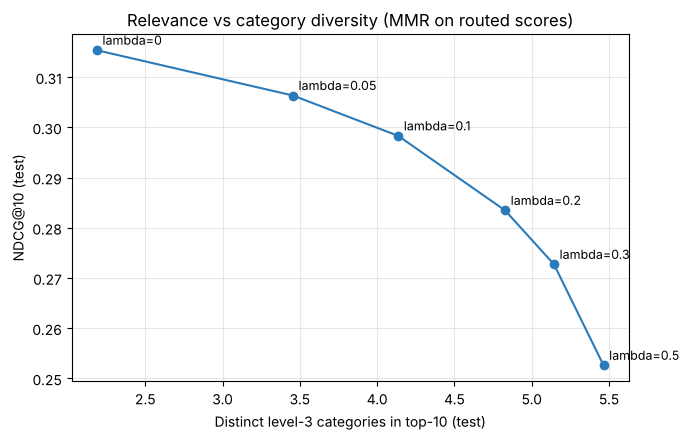

In [10]:
if RUN_STEP:
        val["routed"], _ = route_scores(val, "full_score", "fallback_score", n_hist, best_t)
        trade = []
        for lam in LAMBDAS:
            val["div"] = diversify(val, "routed", cate_map, lam)
            test["div"] = diversify(test, "routed_score", cate_map, lam)
            mv, _ = evaluate(val, "div"); mt, _ = evaluate(test, "div")
            trade.append(dict(lam=lam, val_NDCG10=mv["NDCG@10"], test_NDCG10=mt["NDCG@10"], test_MRR200=mt["MRR@200"], test_P1=mt["P@1"],
                              **{f"val_{k}": v for k, v in diversity_metrics(val, "div", cate_map).items()},
                              **{f"test_{k}": v for k, v in diversity_metrics(test, "div", cate_map).items()}))
        trade = pd.DataFrame(trade); trade.to_csv(RES / "diversity_tradeoff.csv", index=False)
        base = trade.loc[trade.lam == 0].iloc[0]
        best_lam = float(trade[trade.val_NDCG10 >= base.val_NDCG10 - 0.005].lam.max())
        print(trade[["lam", "val_NDCG10", "test_NDCG10", "test_MRR200", "test_P1", "test_distinct_categories_top10"]].round(4).to_string(index=False))
        print(f"\nselected lambda = {best_lam}")

        fig, ax = plt.subplots(figsize=(7, 4.5))
        ax.plot(trade.test_distinct_categories_top10, trade.test_NDCG10, "o-", color="#2b7bba")
        for _, r in trade.iterrows():
            ax.annotate(f"lambda={r.lam:g}", (r.test_distinct_categories_top10, r.test_NDCG10), textcoords="offset points", xytext=(4, 4), fontsize=9)
        ax.set_xlabel("Distinct level-3 categories in top-10 (test)"); ax.set_ylabel("NDCG@10 (test)")
        ax.set_title("Relevance vs category diversity (MMR on routed scores)"); ax.grid(alpha=.3)
        plt.tight_layout(); fig.savefig(FIG / "fig_diversity_tradeoff.png", dpi=150); plt.show()

**Reading.** Every lambda above 0 costs relevance: the mildest setting buys about 1.3 more distinct
categories in the top 10 for roughly 0.009 NDCG@10, and P@1 is untouched by construction (the best item is
never displaced). For *search* re-ranking this is expected: a slate answers one query and its relevant items
sit in one or two categories. Diversification is a merchandising decision with a measurable price, not a
ranking improvement, so the validation rule selects lambda = 0 and the curve is kept for the business discussion.

### A.8 Final scores and saved outputs

In [11]:
if RUN_STEP:
        test["final_score"] = diversify(test, "routed_score", cate_map, best_lam)
        final_m, final_n = evaluate(test, "final_score"); full_m, _ = evaluate(test, "full_score")
        test[["session_id", "cand_wid", "label", "full_score", "fallback_score", "routed_score", "final_score", "history_group"]].to_parquet(OUT / "test_pred_step7.parquet", index=False)
        fallback.save_model(str(OUT / "lgb_fallback_history_free.txt"))
        summary = dict(full_model_source=full_source, history_free_features=HISTORY_FREE, fallback_best_iteration=fallback.best_iteration,
            routing=dict(selected_threshold=best_t, rule="max validation NDCG@10 (ties -> smaller threshold)",
                         cold_test_sessions=int(test.loc[cold_t, "session_id"].nunique()), cold_test_share=float(cold_t.mean()), routed_minus_full_test=routed_vs_full),
            diversification=dict(selected_lambda=best_lam, top_k=TOP_K, rule="largest lambda with validation NDCG@10 within 0.005 of lambda=0", category_key="cate_id_3"),
            test_full=full_m, test_final=final_m, test_positive_queries=final_n,
            interpretation="one seed; thresholds and lambda selected on validation only; bootstrap reflects query resampling for fixed models")
        (RES / "results_coldstart_diversity.json").write_text(json.dumps(summary, indent=2))
        print(f"test NDCG@10  full = {full_m['NDCG@10']:.4f}   final (routed T={best_t}, lambda={best_lam}) = {final_m['NDCG@10']:.4f}")
        print("written:", [p.name for p in [RES/'results_coldstart_diversity.json', RES/'coldstart_segments.csv', RES/'coldstart_threshold_selection.csv', RES/'diversity_tradeoff.csv', OUT/'test_pred_step7.parquet', OUT/'lgb_fallback_history_free.txt', FIG/'fig_diversity_tradeoff.png']])

test NDCG@10  full = 0.3159   final (routed T=1, lambda=0.0) = 0.3154
written: ['results_coldstart_diversity.json', 'coldstart_segments.csv', 'coldstart_threshold_selection.csv', 'diversity_tradeoff.csv', 'test_pred_step7.parquet', 'lgb_fallback_history_free.txt', 'fig_diversity_tradeoff.png']


# Part B: Saved results

Reads whatever Part A wrote to the run directory; if the run directory has no Step 7 results yet, it falls
back to the copy committed in `artifacts/step7_draft_artifacts`.

### B.1 Cold-start results

In [12]:
saved_dir = RES if (RES / "results_coldstart_diversity.json").exists() else PROJECT_ROOT / "artifacts" / "step7_draft_artifacts"
print("reading saved results from:", saved_dir)
result = json.loads((saved_dir / "results_coldstart_diversity.json").read_text(encoding="utf-8"))
print("selected threshold T      :", result["routing"]["selected_threshold"])
print("selected lambda           :", result["diversification"]["selected_lambda"])
print("test NDCG@10 full model   :", round(result["test_full"]["NDCG@10"], 4))
print("test NDCG@10 final scores :", round(result["test_final"]["NDCG@10"], 4))
ci = result["routing"]["routed_minus_full_test"]
print(f"routed minus full         : {ci['delta']:+.4f}  95% CI [{ci['ci95'][0]:+.4f}, {ci['ci95'][1]:+.4f}]")

seg = pd.read_csv(saved_dir / "coldstart_segments.csv")
pivot = seg.pivot(index="history_group", columns="model", values="NDCG@10")
pivot["positive_queries"] = seg[seg.model == "full"].set_index("history_group").positive_queries
display(pivot.round(4))
display(pd.read_csv(saved_dir / "coldstart_threshold_selection.csv").round(4))

reading saved results from: draft_run
selected threshold T      : 1
selected lambda           : 0.0
test NDCG@10 full model   : 0.3159
test NDCG@10 final scores : 0.3154
routed minus full         : -0.0005  95% CI [-0.0016, +0.0004]


model,fallback_history_free,full,routed,positive_queries
history_group,,,,
ALL,0.2731,0.3159,0.3154,2965
limited(1-2),0.2886,0.3090,0.2847,63
long(>100),0.2658,0.3144,0.3144,1293
medium(21-100),0.2672,0.3016,0.3016,1115
short(6-20),0.3040,0.3541,0.3541,393
very_short(3-5),0.3035,0.3493,0.3493,101


,threshold,val_NDCG10,val_positive_queries,val_cold_sessions
0,-1,0.3114,2967,0
1,0,0.3114,2967,0
2,1,0.3117,2967,53
3,2,0.3117,2967,98
4,3,0.3116,2967,126
5,5,0.3097,2967,202
6,10,0.3071,2967,334
7,20,0.3028,2967,600


### B.2 Diversity trade-off

In [13]:
trade_saved = pd.read_csv(saved_dir / "diversity_tradeoff.csv")
display(trade_saved[["lam", "val_NDCG10", "test_NDCG10", "test_MRR200", "test_P1", "test_distinct_categories_top10"]].round(4))

,lam,val_NDCG10,test_NDCG10,test_MRR200,test_P1,test_distinct_categories_top10
0,0.00,0.3117,0.3154,0.3271,0.2044,2.1870
1,0.05,0.3027,0.3064,0.3241,0.2044,3.4553
2,0.10,0.2926,0.2983,0.3212,0.2044,4.1363
3,0.20,0.2766,0.2835,0.3138,0.2044,4.8277
4,0.30,0.2652,0.2727,0.3073,0.2044,5.1440
5,0.50,0.2441,0.2526,0.2909,0.2044,5.4647


# Summary

* A **history-free fallback** and a validation-selected **router** were built. The fallback loses to the full
  ranker in every history segment, the sample has no zero-history users, and the routed combination changes
  test NDCG@10 by a few ten-thousandths with an interval that includes zero. **Decision: keep one model for
  all users.** Cold start lives on the item side.
* **Category MMR** was built and priced: the mildest setting gives about 1.3 more categories in the top 10 for
  about 0.009 NDCG@10. **Decision: lambda = 0**; the curve is reported as a business trade-off.
* Both are kept as diagnostics (report Section 3.5, rubric Aspect 4). The six further AI-suggested changes
  are dispositioned in `STEP7_COLDSTART_DIVERSITY.md`.